# 00b · Event Timeline (Phase P1 review)

A visual check of the hand-coded policy and infrastructure events in `drivers/events.csv`. These dates
drive the causal tests (H3, H4, H9), so each one must be right **before** any outcome data is linked to it.

Status legend: **verified** = two independent sources; anything else is resolved or dropped in P2.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from drivers.config import ROOT, FIG, NAME, COUNTRIES

ev = pd.read_csv(ROOT / "drivers" / "events.csv", parse_dates=["date"])
print(f"{len(ev)} events across {ev.iso3.nunique()} countries")
ev.groupby(["category", "status"]).size().unstack(fill_value=0)

39 events across 9 countries


status,needs_second_source,verified,verified_announcement_date
category,,,
ban,0,1,0
cross_border_rail,0,1,0
crypto_regime,1,9,0
digital_bank,0,2,3
lending_rule,0,1,0
payment_rail,3,12,0
ride_hailing_rule,0,6,0


## Timeline by country

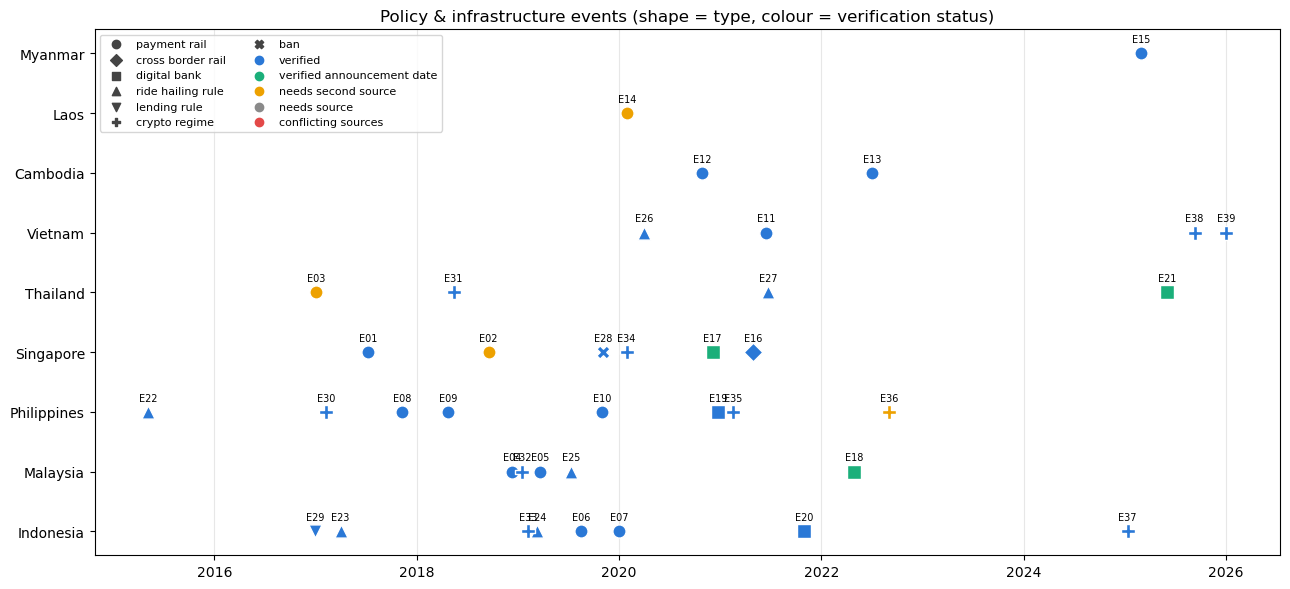

In [2]:
order = [c for c in COUNTRIES if c in set(ev.iso3)]
marker = {"payment_rail": "o", "cross_border_rail": "D", "digital_bank": "s", "ride_hailing_rule": "^",
          "lending_rule": "v", "crypto_regime": "P", "ban": "X"}
color = {"verified": "#2a78d6", "verified_announcement_date": "#1baf7a", "needs_second_source": "#eda100", "needs_source": "#8a8a8a",
         "conflicting_sources": "#e34948"}
fig, ax = plt.subplots(figsize=(13, 6))
for _, r in ev.iterrows():
    y = order.index(r.iso3)
    ax.scatter(r.date, y, marker=marker[r.category], s=90, color=color[r.status], edgecolor="white", zorder=3)
    ax.annotate(r.event_id, (r.date, y), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=7)
ax.set_yticks(range(len(order)), [NAME[c] for c in order])
ax.grid(axis="x", alpha=.3)
for cat, m in marker.items():
    ax.scatter([], [], marker=m, color="#444", label=cat.replace("_", " "))
for st, c in color.items():
    ax.scatter([], [], marker="o", color=c, label=st.replace("_", " "))
ax.legend(ncol=2, fontsize=8, loc="upper left")
ax.set_title("Policy & infrastructure events (shape = type, colour = verification status)")
plt.tight_layout(); plt.savefig(FIG / "00b_event_timeline.png", dpi=150); plt.show()

## Events still needing work

In [3]:
todo = ev[ev.status != "verified"][["event_id", "iso3", "date", "category", "description", "status"]]
todo.assign(country=todo.iso3.map(NAME)).drop(columns="iso3")

,event_id,date,category,description,status,country
1,E02,2018-09-17,payment_rail,SGQR unified national QR code launched,needs_second_source,Singapore
2,E03,2017-01-01,payment_rail,PromptPay real-time transfers live (registrati...,needs_second_source,Thailand
13,E14,2020-01-29,payment_rail,LAO QR national QR system officially launched ...,needs_second_source,Laos
16,E17,2020-12-04,digital_bank,MAS announces successful digital bank licence ...,verified_announcement_date,Singapore
17,E18,2022-04-29,digital_bank,BNM announces five digital bank licences (oper...,verified_announcement_date,Malaysia
20,E21,2025-06-01,digital_bank,Bank of Thailand approves three virtual bank a...,verified_announcement_date,Thailand
35,E36,2022-09-01,crypto_regime,BSP moratorium on new VASP licences (three years),needs_second_source,Philippines
